In [1]:
from pathlib import Path

# enable ipympl widgets for zoom
# %matplotlib widget
#%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import pint_pandas  # needed for initialization
import numpy as np

In [2]:
#sns.set_theme()
#sns.set_theme(style="white")
#sns.set_theme(style="whitegrid")
#sns.set_theme(style="ticks")
sns.set_theme(
    style="ticks",
    context="paper",
    rc={
        "axes.linewidth": 0.8,
        "xtick.direction": "out",
        "ytick.direction": "out"
    }
)

In [3]:
def import_dataset(filename: Path):
    df = pd.read_csv(filename, header=[0, 1])

    names = df.columns.get_level_values(0)
    units = df.columns.get_level_values(1)

    df.columns = names  # flatten
    if 'timestamp' in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], format="ISO8601")
    for col, unit in zip(names, units):  # apply units
        if unit != "No Unit":
            df[col] = df[col].astype(f"pint[{unit}]")

    return df

In [4]:
def load_all(resources_folder: Path):
    frames = []
    for response in ["tp", "ee_total", "ee_net"]:
        for threading in ["single", "multi"]:
            for mode in ["compress", "decompress"]:
                df = import_dataset(resources_folder / f"{response}_effect_size_{threading}_{mode}_measurements.csv")
                frames.append(df)
    result = pd.concat(
        frames,
        ignore_index=True,
    )
    return result

In [14]:
experiment_folder = Path("../data_processing")
resources_folder = experiment_folder / "resources"

image_folder = Path.cwd() / "resources/images"
image_folder.mkdir(parents=True, exist_ok=True)

df = load_all(resources_folder)

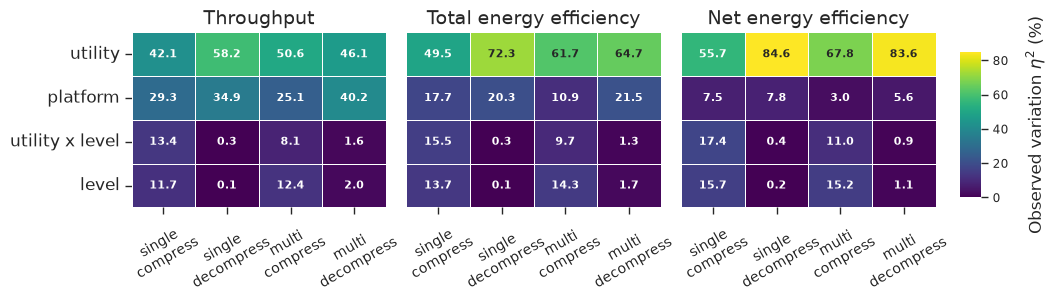

In [31]:
stratum_map = {
    ("single", "compress"): "single\ncompress",
    ("single", "decompress"): "single\ndecompress",
    ("multi", "compress"): "multi\ncompress",
    ("multi", "decompress"): "multi\ndecompress",
}

df["stratum"] = [
    stratum_map[(threading, mode)]
    for threading, mode in zip(df["threading"], df["mode"])
]

stratum_order = [
    "single\ncompress",
    "single\ndecompress",
    "multi\ncompress",
    "multi\ndecompress",
]

response_order = ["throughput", "energy_efficiency_total", "energy_efficiency_net"]

response_titles = {
    "throughput": "Throughput",
    "energy_efficiency_total": "Total energy efficiency",
    "energy_efficiency_net": "Net energy efficiency",
}

# Retain effects reaching at least min_effect_size % in any model.
min_effect_size = 10
effect_maxima = (
    df.groupby("effect")["eta2_pct"]
      .max()
      .sort_values(ascending=False)
)
effect_order = effect_maxima[effect_maxima >= min_effect_size].index.tolist()
plot_df = df[df["effect"].isin(effect_order)]

# Use one common scale so that colors are comparable across panels.
vmax = plot_df["eta2_pct"].max()

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 2.5),
    sharey=True
)

fig.subplots_adjust(
    left=0.23,
    right=0.90,
    bottom=0.18,
    top=0.88,
    wspace=0.08
)

cbar_ax = fig.add_axes([0.92, 0.22, 0.018, 0.58])

for index, (response, ax) in enumerate(zip(response_order, axes)):
    matrix = (
        plot_df[plot_df["response"] == response]
        .pivot(
            index="effect",
            columns="stratum",
            values="eta2_pct"
        )
        .reindex(
            index=effect_order,
            columns=stratum_order
        )
    )

    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        vmin=0,
        vmax=vmax,
        annot=True,
        fmt=".1f",
        linewidths=0.5,
        linecolor="white",
        mask=matrix.isna(),
        cbar=(index == 2),
        cbar_ax=cbar_ax if index == 2 else None,
        annot_kws={"fontsize": 8, "fontweight": "bold"},
    )

    ax.set_title(response_titles[response], fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("")
    #ax.set_xlabel("Operation", fontsize=12)
    #ax.set_ylabel("Effect", fontsize=12)    
    ax.tick_params(
        axis="x", 
        rotation=30,
        labelsize=10,
    )

    if index > 0:
        ax.tick_params(
            axis="y",
            which="both",
            left=False,
            labelleft=False,
        )
    else:
        ax.tick_params(axis="y", labelrotation=0, labelsize=12)

cbar_ax.set_ylabel(
    r"Observed variation $\eta^2$ (%)",
    rotation=90,
    labelpad=12,
    fontsize=12,
)

file_name = image_folder / f"factor_effect_heatmap.pdf"
#print("generate: %s" % file_name)
fig.savefig(file_name, bbox_inches="tight")

plt.show()